# 06.2 — Attention From Scratch

The core of every transformer, built piece by piece: embeddings, scaled dot-product attention, masks, multi-head attention,
positional encodings (sinusoidal and RoPE), the transformer block, and encoder vs decoder models. Each piece is checked against PyTorch's own implementation.

## What's in this notebook

- 1\. From tokens to vectors: embeddings
- 2\. The idea of attention: queries, keys and values
- 3\. Scaled dot-product attention
- 4\. Why divide by √d
- 5\. Masks: causal and padding
- 6\. Multi-head attention
- 7\. Positions: sinusoidal, learned and RoPE
- 8\. Watching attention learn a task
- 9\. The transformer block
- 10\. Encoder, decoder and encoder-decoder
- 11\. The cost of attention, and FlashAttention
- 12\. Trade-offs
- 13\. Interview questions
- 14\. In my own words

In [1]:
import math
import time

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn


def get_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def synchronize(device: torch.device) -> None:
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


device = get_device()
torch.manual_seed(0)
print("device:", device)

device: mps


# 1. FROM TOKENS TO VECTORS: EMBEDDINGS

The tokenizer (06.1) turns text into ids. An **embedding layer** turns each id into a learned vector of size `d_model`:
it's a lookup table with one row per token, the same as multiplying a one-hot vector by a weight matrix, but without the multiplication.
During training, tokens used in similar contexts end up with similar vectors.

In [2]:
vocab_size, d_model = 10, 4
embedding = nn.Embedding(vocab_size, d_model)
ids = torch.tensor([[3, 7, 3]])                                   # a "sentence" of 3 token ids

looked_up = embedding(ids)
one_hot = F.one_hot(ids, vocab_size).float() @ embedding.weight     # the same thing as a matrix multiply
print("ids", tuple(ids.shape), "-> vectors", tuple(looked_up.shape))
print("lookup equals one-hot x weight matrix:", torch.allclose(looked_up, one_hot))
print("the same token gets the same vector, wherever it appears:", torch.equal(looked_up[0, 0], looked_up[0, 2]))

ids (1, 3) -> vectors (1, 3, 4)
lookup equals one-hot x weight matrix: True
the same token gets the same vector, wherever it appears: True


The same token always gets the same vector, wherever it appears in the sentence. Two things are missing, and the rest of this notebook adds them:
**context** (the meaning of "bank" depends on the other words), via attention, and **position**, via positional encodings.

# 2. THE IDEA OF ATTENTION: QUERIES, KEYS AND VALUES

**Attention** lets every token build a new vector as a weighted average of all the tokens' information, with weights it computes itself.
Each token's vector is projected three ways:
- a **query** `q`: what this token is looking for;
- a **key** `k`: what this token offers, to be matched against queries;
- a **value** `v`: the information this token passes on if it is chosen.

Like a search engine: the query is compared with every key; good matches get high weights; the result is the weighted mix of their values.
In "The animal didn't cross the street because **it** was tired", the query of "it" should match the key of "animal" and take in its value.

# 3. SCALED DOT-PRODUCT ATTENTION

```text
Attention(Q, K, V) = softmax(Q · Kᵀ / √d_k) · V

Q · Kᵀ      (tokens × tokens)    every query compared with every key: one score per pair
/ √d_k                            keeps the scores in a reasonable range (section 4)
softmax     over each row         each row becomes weights that sum to 1
· V         (tokens × d_v)        each output is the weighted average of the values
```

The whole operation is matrix multiplies, so every token is processed in parallel; there's no step-by-step loop as in an RNN.

In [3]:
def attention(q, k, v, mask=None):
    """q, k, v: (..., tokens, d). mask: True where attention is allowed."""
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])      # (..., tokens, tokens)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))           # forbidden pairs get weight 0 after softmax
    weights = scores.softmax(dim=-1)
    return weights @ v, weights


x = torch.randn(1, 5, 8)                                            # 1 sentence, 5 tokens, 8 dimensions
W_q, W_k, W_v = (nn.Linear(8, 8, bias=False) for _ in range(3))
out, weights = attention(W_q(x), W_k(x), W_v(x))

print("output:", tuple(out.shape), "| attention weights:", tuple(weights.shape))
print("each row of weights sums to 1:", torch.allclose(weights.sum(-1), torch.ones(1, 5)))
print("matches F.scaled_dot_product_attention:", torch.allclose(out, F.scaled_dot_product_attention(W_q(x), W_k(x), W_v(x)), atol=1e-6))
print("weights of token 0 over the 5 tokens:", weights[0, 0].detach().numpy().round(3))

output: (1, 5, 8) | attention weights: (1, 5, 5)
each row of weights sums to 1: True
matches F.scaled_dot_product_attention: True
weights of token 0 over the 5 tokens: [0.202 0.228 0.209 0.184 0.176]


# 4. WHY DIVIDE BY √d

If query and key entries are roughly independent with variance 1, their dot product over `d` dimensions has variance `d`, so its spread grows like √d.
Large scores push softmax towards a one-hot output: one token gets nearly all the weight, and the gradients of the others become almost zero.
Dividing by √d brings the spread back to about 1, whatever the head size.

In [4]:
for d in [16, 64, 256, 1024]:
    q, k = torch.randn(10_000, d), torch.randn(10_000, d)
    dots = (q * k).sum(dim=1)
    scores = torch.randn(8, d) @ torch.randn(d, 8)                # 8 queries x 8 keys
    top_raw = scores.softmax(-1).max(-1).values.mean()
    top_scaled = (scores / math.sqrt(d)).softmax(-1).max(-1).values.mean()
    print(f"d = {d:>4}: dot-product std {dots.std():5.1f} (√d = {math.sqrt(d):4.1f}), scaled std {(dots / math.sqrt(d)).std():.2f} | "
          f"average top softmax weight over 8 keys: unscaled {top_raw:.2f}, scaled {top_scaled:.2f}")

d =   16: dot-product std   4.0 (√d =  4.0), scaled std 0.99 | average top softmax weight over 8 keys: unscaled 0.69, scaled 0.33
d =   64: dot-product std   8.0 (√d =  8.0), scaled std 1.00 | average top softmax weight over 8 keys: unscaled 0.89, scaled 0.38
d =  256: dot-product std  16.2 (√d = 16.0), scaled std 1.01 | average top softmax weight over 8 keys: unscaled 0.98, scaled 0.41


d = 1024: dot-product std  32.1 (√d = 32.0), scaled std 1.00 | average top softmax weight over 8 keys: unscaled 0.96, scaled 0.32


The spread of the dot products follows √d exactly (4, 8, 16, 32), and dividing by √d brings it back to 1. Without scaling, once d ≥ 64 the softmax over 8 keys already puts 0.89–0.98 of the weight on a single key: nearly one-hot, so the other keys get almost no gradient. Scaled, the top weight stays around 0.3–0.4 and every key keeps contributing to learning.

# 5. MASKS: CAUSAL AND PADDING

A **mask** removes some query–key pairs by setting their scores to −∞ before the softmax, so their weight becomes exactly 0.
- **Causal (look-ahead) mask:** token t may only attend to tokens 0..t. GPT-style models use it so that, while training on whole sentences, no token can see the words it's supposed to predict.
- **Padding mask:** nobody attends to `[PAD]` tokens (built from the attention mask in 06.1).

In [5]:
T = 5
causal = torch.tril(torch.ones(T, T, dtype=torch.bool))            # lower triangle: True = allowed
_, causal_weights = attention(W_q(x), W_k(x), W_v(x), mask=causal)
print("causal mask:\n", causal.int())
print("attention weights with the causal mask:\n", causal_weights[0].detach().numpy().round(2))

x_changed = x.clone()
x_changed[0, 4] = torch.randn(8)                                    # change only the LAST token
out_a, _ = attention(W_q(x), W_k(x), W_v(x), mask=causal)
out_b, _ = attention(W_q(x_changed), W_k(x_changed), W_v(x_changed), mask=causal)
print("outputs of tokens 0-3 unchanged after changing token 4:", torch.allclose(out_a[0, :4], out_b[0, :4]))

causal mask:
 tensor([[1, 0, 0, 0, 0],
        [1, 1, 0, 0, 0],
        [1, 1, 1, 0, 0],
        [1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1]], dtype=torch.int32)
attention weights with the causal mask:
 [[1.   0.   0.   0.   0.  ]
 [0.43 0.57 0.   0.   0.  ]
 [0.33 0.17 0.5  0.   0.  ]
 [0.23 0.19 0.22 0.36 0.  ]
 [0.25 0.19 0.18 0.2  0.17]]
outputs of tokens 0-3 unchanged after changing token 4: True


Each row only has weights on the diagonal and to its left, and changing the last token leaves the earlier outputs untouched: no information flows backwards in time.

# 6. MULTI-HEAD ATTENTION

One attention pattern per layer is limiting: a word may need to look at its subject, the previous word and a matching bracket all at once.
**Multi-head attention** splits `d_model` into `h` smaller heads (for example 768 = 12 × 64), runs attention in each independently, concatenates the results
and mixes them with an output projection. It costs about the same as one big head.

```text
x ─► Q, K, V projections ─► split into h heads ─► attention in each head ─► concatenate ─► output projection
```

In [6]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads, self.head_dim = n_heads, d_model // n_heads
        self.q, self.k, self.v = nn.Linear(d_model, d_model), nn.Linear(d_model, d_model), nn.Linear(d_model, d_model)
        self.out = nn.Linear(d_model, d_model)

    def forward(self, x, mask=None):
        B, T, D = x.shape
        split = lambda t: t.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)     # (B, heads, T, head_dim)
        out, weights = attention(split(self.q(x)), split(self.k(x)), split(self.v(x)), mask)
        out = out.transpose(1, 2).reshape(B, T, D)                                      # concatenate the heads
        return self.out(out), weights


mha = MultiHeadAttention(d_model=16, n_heads=4)
reference = nn.MultiheadAttention(16, 4, batch_first=True)
with torch.no_grad():                                                                # give PyTorch's version the same weights
    reference.in_proj_weight.copy_(torch.cat([mha.q.weight, mha.k.weight, mha.v.weight]))
    reference.in_proj_bias.copy_(torch.cat([mha.q.bias, mha.k.bias, mha.v.bias]))
    reference.out_proj.weight.copy_(mha.out.weight)
    reference.out_proj.bias.copy_(mha.out.bias)

x16 = torch.randn(2, 5, 16)
ours, head_weights = mha(x16)
print("output", tuple(ours.shape), "| attention weights per head", tuple(head_weights.shape))
print("matches nn.MultiheadAttention:", torch.allclose(ours, reference(x16, x16, x16)[0], atol=1e-6))

output (2, 5, 16) | attention weights per head (2, 4, 5, 5)
matches nn.MultiheadAttention: True


# 7. POSITIONS: SINUSOIDAL, LEARNED AND ROPE

Attention itself ignores order: shuffle the input tokens and the outputs are shuffled the same way, with identical values.
"Dog bites man" and "man bites dog" would look the same. Position has to be added explicitly.

In [7]:
perm = torch.tensor([3, 0, 4, 1, 2])
out_original, _ = mha(x16)
out_shuffled, _ = mha(x16[:, perm])
print("shuffling the tokens just shuffles the outputs:", torch.allclose(out_original[:, perm], out_shuffled, atol=1e-6))

shuffling the tokens just shuffles the outputs: True


| Method | How it works | Used in |
|---|---|---|
| **sinusoidal** | add fixed sine and cosine waves of different frequencies to each embedding | the original transformer |
| **learned absolute** | add a trained vector per position (`nn.Embedding(max_len, d)`); can't go beyond `max_len` | BERT, GPT-2 |
| **RoPE** (rotary) | rotate each query and key by an angle proportional to its position; the dot product then depends only on the *distance* between tokens | LLaMA, Mistral, Qwen, most modern LLMs |
| **ALiBi** | add a penalty to attention scores that grows with distance | BLOOM, MPT |

RoPE's relative-distance property is why context windows can be stretched after training (position interpolation, YaRN), and it's the standard today.

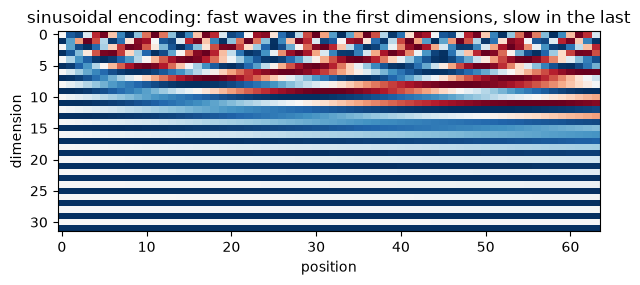

RoPE score, query at position   2, key at   5 (distance 3): 8.7871
RoPE score, query at position 102, key at 105 (distance 3): 8.7871
RoPE score, query at position 500, key at 503 (distance 3): 8.7871


In [8]:
def sinusoidal(max_len: int, d: int) -> torch.Tensor:
    pos = torch.arange(max_len).unsqueeze(1)
    freq = torch.exp(-math.log(10000.0) * torch.arange(0, d, 2) / d)
    pe = torch.zeros(max_len, d)
    pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * freq), torch.cos(pos * freq)
    return pe


def rope(x: torch.Tensor, positions: torch.Tensor) -> torch.Tensor:
    """Rotate pairs of dimensions of x (..., d) by angles that grow with the position."""
    d = x.shape[-1]
    freq = 10000.0 ** (-torch.arange(0, d, 2) / d)
    angle = positions.unsqueeze(-1) * freq                                   # (..., d/2)
    x1, x2 = x[..., 0::2], x[..., 1::2]
    rotated = torch.stack([x1 * angle.cos() - x2 * angle.sin(), x1 * angle.sin() + x2 * angle.cos()], dim=-1)
    return rotated.flatten(-2)


plt.figure(figsize=(7, 2.6))
plt.imshow(sinusoidal(64, 32).T, aspect="auto", cmap="RdBu")
plt.xlabel("position")
plt.ylabel("dimension")
plt.title("sinusoidal encoding: fast waves in the first dimensions, slow in the last")
plt.show()

q, k = torch.randn(64), torch.randn(64)
for m, n in [(2, 5), (102, 105), (500, 503)]:
    score = rope(q, torch.tensor(float(m))) @ rope(k, torch.tensor(float(n)))
    print(f"RoPE score, query at position {m:>3}, key at {n:>3} (distance 3): {score.item():.4f}")

With RoPE, the query–key score is the same whenever the distance is the same (3), whether the tokens sit at positions 2 and 5 or 500 and 503: the model sees relative positions.

# 8. WATCHING ATTENTION LEARN A TASK

A one-layer, one-head attention model with learned position embeddings is trained to **reverse** a sequence of 8 random digits.
Output position i must copy input position 7 − i, so a correct solution must learn to look at exactly one, mirrored position.

test accuracy: 1.000   example: [5, 9, 4, 8, 3, 3, 1, 1] -> [1, 1, 3, 3, 8, 4, 9, 5]


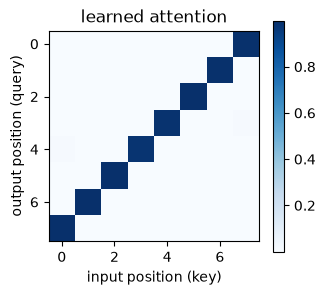

In [9]:
class Reverser(nn.Module):
    def __init__(self, vocab: int = 10, length: int = 8, d: int = 32):
        super().__init__()
        self.tok, self.pos = nn.Embedding(vocab, d), nn.Embedding(length, d)
        self.attn = MultiHeadAttention(d, n_heads=1)
        self.head = nn.Linear(d, vocab)

    def forward(self, ids):
        x = self.tok(ids) + self.pos(torch.arange(ids.shape[1]))
        out, weights = self.attn(x)
        return self.head(out), weights


torch.manual_seed(0)
reverser = Reverser()
optimizer = torch.optim.Adam(reverser.parameters(), lr=3e-3)
gen = torch.Generator().manual_seed(0)
for step in range(1500):
    ids = torch.randint(0, 10, (64, 8), generator=gen)
    logits, _ = reverser(ids)
    loss = F.cross_entropy(logits.reshape(-1, 10), ids.flip(1).reshape(-1))
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

test = torch.randint(0, 10, (1000, 8), generator=torch.Generator().manual_seed(1))
with torch.no_grad():
    logits, weights = reverser(test)
print(f"test accuracy: {(logits.argmax(-1) == test.flip(1)).float().mean():.3f}   example: {test[0].tolist()} -> {logits[0].argmax(-1).tolist()}")

plt.figure(figsize=(3.4, 3))
plt.imshow(weights[0, 0], cmap="Blues")
plt.xlabel("input position (key)")
plt.ylabel("output position (query)")
plt.title("learned attention")
plt.colorbar()
plt.show()

The model reverses unseen sequences perfectly (accuracy 1.000), and the attention map shows how: a clean anti-diagonal. Output position 0 attends to input position 7, position 1 to position 6, and so on. It learned this purely from the position embeddings, since the digits are random. Heads in real models learn patterns such as "attend to the previous token" or "attend to the matching bracket" the same way.

# 9. THE TRANSFORMER BLOCK

A transformer is a stack of identical blocks. Each block has two sub-layers, each wrapped in normalization and a residual connection (03.2), in the modern **pre-norm** layout:

```text
x = x + MultiHeadAttention(LayerNorm(x))      tokens exchange information
x = x + FeedForward(LayerNorm(x))             each token is processed on its own: Linear(d → 4d) → GELU → Linear(4d → d)
```

- Attention **mixes information between tokens**; the feed-forward network (MLP) **transforms each token** and holds much of the model's stored knowledge.
- The feed-forward layer is usually 4 times wider than `d_model`. LLaMA-style models use **SwiGLU** (a gated variant with SiLU) and RMSNorm instead of LayerNorm.
- Each block has about 12·d² parameters: 4·d² in attention (Q, K, V and output projections) and 8·d² in the feed-forward layer.

In [10]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model: int, n_heads: int, ff_mult: int = 4, dropout: float = 0.0):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, n_heads)
        self.ff = nn.Sequential(nn.Linear(d_model, ff_mult * d_model), nn.GELU(), nn.Linear(ff_mult * d_model, d_model))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        x = x + self.drop(self.attn(self.norm1(x), mask)[0])
        x = x + self.drop(self.ff(self.norm2(x)))
        return x


count = lambda m: sum(p.numel() for p in m.parameters())
block = TransformerBlock(d_model=768, n_heads=12)
embeddings = 50257 * 768 + 1024 * 768                    # GPT-2 token and position embeddings
total = 12 * count(block) + embeddings + 2 * 768          # 12 blocks + embeddings + final LayerNorm
print(f"one block with d_model = 768: {count(block):,} parameters (12·d² = {12 * 768 ** 2:,})")
print(f"GPT-2 small layout (12 blocks): {total / 1e6:.1f}M parameters, of which embeddings {embeddings / 1e6:.1f}M")
print("a block keeps the shape:", tuple(block(torch.randn(2, 10, 768)).shape))

one block with d_model = 768: 7,087,872 parameters (12·d² = 7,077,888)
GPT-2 small layout (12 blocks): 124.4M parameters, of which embeddings 39.4M
a block keeps the shape: (2, 10, 768)


One block with d_model = 768 has 7.09M parameters: 12·d² plus small bias and norm terms. Twelve blocks plus GPT-2's embeddings give 124.4M parameters, the published size of GPT-2 small, so this block has exactly GPT-2's layout. Almost a third of that model is the embedding table.

# 10. ENCODER, DECODER AND ENCODER-DECODER

| Type | Attention | Trained to | Good at | Examples |
|---|---|---|---|---|
| **encoder-only** | bidirectional: every token sees every other | fill in masked words (masked language modelling) | understanding: classification, entity tagging, embeddings for search | BERT, RoBERTa, sentence-transformers |
| **decoder-only** | causal: each token sees only earlier tokens | predict the next token | generating text; with scale, almost everything | GPT, LLaMA, Claude, Mistral, Qwen |
| **encoder-decoder** | encoder bidirectional; decoder causal plus **cross-attention** to the encoder's outputs | turn one sequence into another | translation, summarization, speech to text | the original transformer, T5, BART, Whisper |

**Cross-attention** is ordinary attention where the queries come from the decoder and the keys and values from the encoder: the decoder looks up the parts of the input it needs.
Decoder-only models won for general LLMs because next-token prediction works on any text without labels and one model can handle every task through prompting.

# 11. THE COST OF ATTENTION, AND FLASHATTENTION

The score matrix has one entry per pair of tokens, so time and memory grow with the **square** of the sequence length:
doubling the context makes attention 4 times more expensive. For 8 heads and 4,096 tokens, the scores alone take 537 MB per sequence in float32.

**FlashAttention** computes exactly the same result without ever storing the full score matrix: it processes blocks of queries and keys inside the GPU's fast on-chip memory
and combines the softmax piece by piece. Memory becomes linear in the sequence length and it runs several times faster, because the bottleneck is memory traffic, not arithmetic.
In PyTorch, `F.scaled_dot_product_attention` picks a fused kernel such as FlashAttention automatically when the hardware supports it.

In [11]:
def naive_attention(q, k, v):
    return (q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])).softmax(-1) @ v


for n in [512, 1024, 2048, 4096]:
    q, k, v = (torch.randn(1, 8, n, 64, device=device) for _ in range(3))
    times = []
    for fn in [naive_attention, F.scaled_dot_product_attention]:
        for _ in range(3):
            fn(q, k, v)
        synchronize(device)
        start = time.perf_counter()
        for _ in range(20):
            fn(q, k, v)
        synchronize(device)
        times.append((time.perf_counter() - start) / 20 * 1000)
    same = torch.allclose(naive_attention(q, k, v), F.scaled_dot_product_attention(q, k, v), atol=1e-4)
    print(f"{n:>4} tokens: naive {times[0]:6.2f} ms, fused {times[1]:6.2f} ms | score matrix {8 * n * n * 4 / 1e6:6.1f} MB | same result: {same}")

 512 tokens: naive   0.98 ms, fused   0.41 ms | score matrix    8.4 MB | same result: True


1024 tokens: naive   1.42 ms, fused   0.80 ms | score matrix   33.6 MB | same result: True


2048 tokens: naive   5.29 ms, fused   3.22 ms | score matrix  134.2 MB | same result: True


4096 tokens: naive  31.82 ms, fused  14.62 ms | score matrix  536.9 MB | same result: True


Both give the same result. On this Mac's GPU the fused kernel is about 1.6–2.4x faster (0.41 ms against 0.98 ms at 512 tokens, 14.6 ms against 31.8 ms at 4,096). Once sequences are long, doubling the length multiplies the naive time by roughly 4–6 (5.3 ms → 31.8 ms from 2,048 to 4,096 tokens), and the score matrix grows from 8 MB to 537 MB. On NVIDIA GPUs, FlashAttention's advantage is larger and its memory stays linear in the length.

Other ways to cut the cost: **sliding-window** attention (each token sees only the last w tokens, as in Mistral), sparse patterns,
**grouped-query attention** (several query heads share one key/value head, which shrinks the KV cache, folder 07), and linear-time alternatives such as state-space models (05.1).

# 12. TRADE-OFFS

| Decision | Options | What you gain and what you pay | Usual choice |
|---|---|---|---|
| Sequence model | RNN / transformer | RNN: linear cost, fixed memory, sequential training. Transformer: parallel training and direct long-range connections, quadratic attention cost | transformer |
| Positional information | sinusoidal / learned / RoPE / ALiBi | sinusoidal: no parameters. Learned: simple, fixed maximum length. RoPE: relative positions, extendable context. ALiBi: good length extrapolation | RoPE |
| Number of heads | few large / many small | many heads: more distinct attention patterns, each head smaller. Few: richer per head | head size 64–128; heads = d_model / head size |
| Norm placement | post-norm / pre-norm | pre-norm trains deep stacks stably (03.2) | pre-norm, with RMSNorm in LLMs |
| Feed-forward | GELU MLP / SwiGLU | SwiGLU: slightly better quality for the same compute, a third weight matrix | SwiGLU in modern LLMs |
| Architecture | encoder / decoder / encoder-decoder | encoder: best embeddings and classification per parameter. Decoder: generation and general use. Encoder-decoder: strong for input-to-output tasks | decoder for LLMs, encoder for embeddings and classification |
| Attention implementation | naive / fused (FlashAttention) | naive: easy to read and modify. Fused: same result, much less memory and faster | `F.scaled_dot_product_attention` in real code |

# 13. INTERVIEW QUESTIONS

### Q1. Explain self-attention, in 30 seconds.
Each token's vector is projected into a query, a key and a value. Each query is compared with every key by a dot product, scaled by √d, and a softmax turns the scores into weights.
Each token's output is the weighted average of all the values. So every token gathers information from the tokens most relevant to it, all in parallel.

### Q2. Why scale by √d_k?
Dot products of d-dimensional vectors with unit-variance entries have variance d. Large scores saturate the softmax into a near one-hot distribution with vanishing gradients.
Dividing by √d keeps the variance around 1 for any head size (section 4).

### Q3. What are Q, K and V, intuitively?
The query is what a token is looking for, the key is what each token can be matched on, and the value is the content it passes along when selected.
All three are learned linear projections of the same input (in self-attention).

### Q4. Why multiple heads?
Each head can learn a different relationship (syntax, coreference, nearby words) in its own lower-dimensional subspace. Their outputs are concatenated and projected,
at about the same cost as one full-size head.

### Q5. What does the causal mask do, and why is it needed?
It blocks attention to future positions by setting those scores to −∞ before the softmax. Decoder models train on whole sequences at once, predicting every next token in parallel;
without the mask each position could simply look at the answer.

### Q6. Why do transformers need positional encodings? Compare sinusoidal, learned and RoPE.
Attention is permutation-equivariant, so without positions word order is invisible (section 7). Sinusoidal encodings add fixed waves; learned embeddings add a trained vector per position but cap the length;
RoPE rotates queries and keys so scores depend on relative distance, which generalizes better and allows context extension. Most modern LLMs use RoPE.

### Q7. What's inside a transformer block?
Pre-norm multi-head self-attention with a residual connection, then a pre-norm position-wise feed-forward network (expand 4x, GELU or SwiGLU, project back) with another residual.
Attention mixes information across tokens; the feed-forward layer processes each token and stores much of the knowledge.

### Q8. How many parameters does a transformer block have?
About 12·d²: 4·d² for the Q, K, V and output projections and 8·d² for a 4x feed-forward layer, plus small bias and norm terms. GPT-2 small (d = 768, 12 blocks) has about 85M in blocks and 124M in total.

### Q9. BERT vs GPT vs T5?
BERT is an encoder with bidirectional attention, pre-trained by masked language modelling; best for understanding and embeddings. GPT is a decoder with causal attention,
pre-trained by next-token prediction; best for generation. T5 is an encoder-decoder that frames every task as text-to-text, with cross-attention from decoder to encoder.

### Q10. What is cross-attention?
Attention whose queries come from one sequence (the decoder) and keys and values from another (the encoder's output, or image features in multimodal models).
It lets the output side look up relevant parts of the input.

### Q11. What's the complexity of self-attention, and how is it reduced?
O(n²·d) time and O(n²) memory for the score matrix, for n tokens. FlashAttention avoids storing the matrix (linear memory, faster, exact).
Sliding-window, sparse and linear attention, and grouped-query attention (for the KV cache) reduce costs further, some approximately.

### Q12. Why did decoder-only models win for LLMs?
Next-token prediction needs no labels, so they train on any text at huge scale, and one model handles every task through prompting and generation.
Training is simple and efficient, and with enough scale they also understand text well enough to replace most encoder uses.

### Q13. What does the feed-forward network do if attention already mixes tokens?
Attention is mostly a weighted averaging of values; the feed-forward layer adds per-token non-linear processing. It holds about two thirds of a block's parameters
and research suggests it stores much of the factual knowledge.

# 14. IN MY OWN WORDS

Write this from memory, without looking above:

- Self-attention, step by step, with the shapes:
- Why √d, why masks, why multiple heads:
- How RoPE encodes position:
- The two sub-layers of a transformer block, and what each does:
- Encoder-only vs decoder-only vs encoder-decoder: